In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/ml_jobs.csv")

print("Original shape:", df.shape)

Original shape: (997, 10)


In [ ]:
df = df.drop(columns=["Unnamed: 0"])#remove unnecessary column

In [3]:
df = df.dropna(subset=["job_description_text"])#remove rows with missing job description

In [4]:
#inspect dublicates
duplicates = df[
    df.duplicated(subset=["job_description_text"], keep=False)
].sort_values("job_description_text")

display(
    duplicates[
        ["job_title", "company_name", "seniority_level"]
    ].head(20)
)

,job_title,company_name,seniority_level
607,Machine Learning Engineer,Aarna Software and Solutions LLC,Entry level
637,Machine Learning Engineer,Aarna Software and Solutions LLC,Entry level
550,Machine Learning Engineer,Baselayer,Entry level
395,Machine Learning Engineer,Baselayer,Entry level
271,Machine Learning Engineer - Fine Tuning,Baseten,Not Applicable
313,Machine Learning Engineer - Fine Tuning,Baseten,Not Applicable
652,"Machine Learning Engineer, Core Engineering",Pinterest,Mid-Senior level
920,"Machine Learning Engineer, Core Engineering",Pinterest,Mid-Senior level
642,Software Engineer - Front End,Stash Hotel Rewards,Mid-Senior level
676,Software Engineer - Front End,Stash Hotel Rewards,Mid-Senior level


In [5]:
df = df.drop_duplicates(
    subset=["job_description_text"],
    keep="first"
)

In [6]:
#Handle missing data
metadata_columns = [
    "company_address_locality",
    "company_address_region",
    "company_website",
    "company_description",
    "seniority_level"
]

df[metadata_columns] = df[metadata_columns].fillna("Unknown")

In [7]:
#check the cleaned dataset
print("Cleaned shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum())

print("\nRemaining duplicate descriptions:")
print(df["job_description_text"].duplicated().sum())

print("\nSeniority distribution:")
print(df["seniority_level"].value_counts())

Cleaned shape: (795, 9)

Remaining missing values:
job_posted_date             0
company_address_locality    0
company_address_region      0
company_name                0
company_website             0
company_description         0
job_description_text        0
seniority_level             0
job_title                   0
dtype: int64

Remaining duplicate descriptions:
0

Seniority distribution:
seniority_level
Mid-Senior level    313
Entry level         251
Not Applicable      129
Internship           62
Associate            27
Unknown               8
Director              4
Executive             1
Name: count, dtype: int64


In [8]:
#Save the cleaned data to a new CSV file
df.to_csv(
    "../data/processed/cleaned_jobs.csv",
    index=False
)

In [9]:
print("Top 30 job titles:")
display(df["job_title"].value_counts().head(30))

Top 30 job titles:


job_title
Machine Learning Engineer                                                                  215
Data Scientist                                                                              38
Senior Machine Learning Engineer                                                            22
Software Engineer, Machine Learning                                                         10
Machine Learning Engineer II                                                                 8
Software Engineer                                                                            7
Machine Learning Engineer III                                                                4
Machine Learning Engineer, Ads Targeting                                                     4
AI/ML Software Engineer                                                                      4
AI Software Engineer                                                                         4
AI/Machine Learning Engineer            

In [10]:
# Explore titles containing relevant keywords

keywords = [
    "data analyst",
    "data scientist",
    "machine learning",
    "ml engineer",
    "ai engineer",
    "artificial intelligence"
]

for keyword in keywords:
    matches = df[
        df["job_title"].str.contains(
            keyword,
            case=False,#means that the search is case-insensitive
            na=False
        )
    ]

    print(f"\n{keyword}: {len(matches)} postings")
    print(matches["job_title"].value_counts().head(10))


data analyst: 0 postings
Series([], Name: count, dtype: int64)

data scientist: 95 postings
job_title
Data Scientist                                          38
Senior Data Scientist, Data Science                      2
Data Scientist / ML Engineer                             2
AI/ML Data Scientist                                     2
Data Scientist Intern                                    2
Senior Data Scientist, Experimentation                   2
Data Scientist - Healthcare & Clinical Data (Remote)     1
Data Scientist - All Levels                              1
ML Engineer/Data Scientist                               1
Data Scientist - req32521                                1
Name: count, dtype: int64

machine learning: 582 postings
job_title
Machine Learning Engineer                        215
Senior Machine Learning Engineer                  22
Software Engineer, Machine Learning               10
Machine Learning Engineer II                       8
Machine Learning Engineer I

In [ ]:
df["description_length"] = (#inspect the length of job descriptions
    df["job_description_text"].str.len()
)

print(df["description_length"].describe())

count      795.000000
mean      4477.450314
std       1860.691102
min        276.000000
25%       3035.500000
50%       4512.000000
75%       5750.000000
max      14137.000000
Name: description_length, dtype: float64


Matplotlib is building the font cache; this may take a moment.


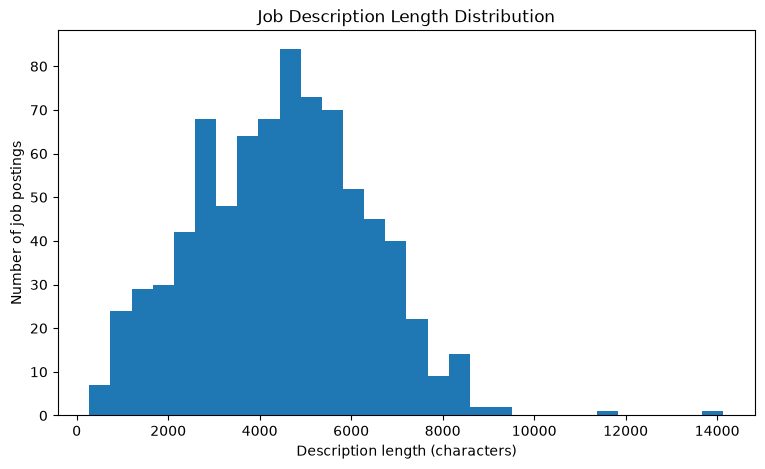

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    df["description_length"],
    bins=30
)

plt.xlabel("Description length (characters)")
plt.ylabel("Number of job postings")
plt.title("Job Description Length Distribution")

plt.show()

In [13]:
import numpy as np

titles = df["job_title"].str.lower()

conditions = [
    titles.str.contains(r"\bdata scientist\b", regex=True),

    titles.str.contains(
        r"\b(ai|artificial intelligence)\b",
        regex=True
    ),

    titles.str.contains(
        r"machine learning|ml engineer",
        regex=True
    )
]

categories = [
    "Data Scientist",
    "AI-related",
    "Machine Learning"
]

df["role_category"] = np.select(
    conditions,
    categories,
    default="Other"
)

print(df["role_category"].value_counts())

role_category
Machine Learning    527
Data Scientist       95
Other                91
AI-related           82
Name: count, dtype: int64


/var/folders/y_/bcmyqz3908q6c40xb7yxxs7h0000gn/T/ipykernel_27361/3658122185.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  titles.str.contains(


In [14]:
for category in df["role_category"].unique():#inspect the top 15 job titles for each role category
    print(f"\n{'='*50}")
    print(category)

    print(
        df.loc[
            df["role_category"] == category,
            "job_title"
        ].value_counts().head(15)
    )


Machine Learning
job_title
Machine Learning Engineer                                                                  215
Senior Machine Learning Engineer                                                            22
Software Engineer, Machine Learning                                                         10
Machine Learning Engineer II                                                                 8
Machine Learning Engineer III                                                                4
Machine Learning Engineer, Ads Targeting                                                     4
Machine Learning Research Engineer                                                           3
Software Engineer - Machine Learning                                                         3
Machine Learning Engineer Intern                                                             2
Machine Learning Engineer Intern (E-commerce-Recommendation) - 2025 Summer/Fall (BS/MS)      2
Software Engineer, Mac

In [26]:
shortest_jobs = df.nsmallest(#identfy the 10 shortest job descriptions
    10,
    "description_length"
)

display(
    shortest_jobs[
        [
            "job_title",
            "company_name",
            "seniority_level",
            "description_length"
        ]
    ]
)
#print full job descriptions for the 10 shortest job descriptions
print("\nJob Descriptions for 10 Shortest Job Descriptions:")
for index, row in shortest_jobs.iterrows():
    print(f"\n{'='*50}")
    print(f"Job Title: {row['job_title']}")
    print(f"Company: {row['company_name']}")
    print("\nJob Description:\n")
    print(row["job_description_text"])

,job_title,company_name,seniority_level,description_length
661,Senior Machine Learning Engineer,Accroid Inc,Mid-Senior level,276
365,Machine Learning Engineer,Lumicity,Mid-Senior level,306
598,Machine Learning Engineer,First Soft Solutions LLC,Mid-Senior level,470
527,Machine Learning Engineer,First Soft Solutions LLC,Mid-Senior level,490
373,Machine Learning Engineer,Compunnel Inc.,Mid-Senior level,590
374,AI/ML Software Engineer,Top AI Start up,Mid-Senior level,679
249,Machine Learning Engineer,Hirechain,Mid-Senior level,738
272,Machine Learning Engineer,Compunnel Inc.,Mid-Senior level,795
645,Software Engineer (Backend AI/ML),Lawrence Harvey,Mid-Senior level,842
443,Machine Learning/AI Engineer,Technology Ventures,Mid-Senior level,858



Job Descriptions for 10 Shortest Job Descriptions:

Job Title: Senior Machine Learning Engineer
Company: Accroid Inc

Job Description:

Familiarity with machine learning frameworks (e.g., TensorFlow, PyTorch, Scikit-learn).Excellent problem-solving skills and the ability to work in a fast-paced environment.Strong communication skills, with the ability to present complex concepts to non-technical stakeholders.

Job Title: Machine Learning Engineer
Company: Lumicity

Job Description:

Senior Machine Learning Engineer (Deep Learning) - Bay AreaExciting stealth-mode AI startup creating state-of-the-art climate models.QualificationsProficient in C++ and PythonExpertise in deep learning architecturesExperience working in a start-up environmentExperience with climate modeling (not required)

Job Title: Machine Learning Engineer
Company: First Soft Solutions LLC

Job Description:

We are actively hiring for Senior Machine Learning EngineerFull TimeExperience: 8+ yearsMust-Have SkillsMinimum o

In [18]:
# Count descriptions below 1000 characters
print(
    "Descriptions below 1000 characters:",
    (df["description_length"] < 1000).sum()
)

# Inspect descriptions between 1000 and 1500 characters
display(
    df[
        (df["description_length"] >= 1000) &
        (df["description_length"] < 1500)
    ][
        [
            "job_title",
            "company_name",
            "seniority_level",
            "description_length"
        ]
    ].head(20)
)

Descriptions below 1000 characters: 16


,job_title,company_name,seniority_level,description_length
117,Machine Learning Engineer,Bask Health,Entry level,1049
118,Machine Learning Engineer,Storytime,Entry level,1498
127,Machine Learning Engineer,Happy Elements,Entry level,1400
128,Data Scientist,hackajob,Mid-Senior level,1054
142,Machine Learning Engineer,Morgan King Technology,Mid-Senior level,1472
224,Machine Learning Engineer,Flair Labs (YC W24),Entry level,1193
329,Machine Learning Engineer,Impax Recruitment,Not Applicable,1395
334,Machine Learning Engineer,SIBLING,Director,1022
367,Machine Learning Engineer,"Sira Consulting, an Inc 5000 company",Associate,1009
430,Machine Learning Research Engineer,Evolve Group,Mid-Senior level,1489


In [17]:
# Exclude very short descriptions for initial screening
candidates = df[
    df["description_length"] >= 1000
].copy()

# Avoid duplicate company/title combinations where possible
candidates = candidates.drop_duplicates(
    subset=["company_name", "job_title"],
    keep="first"
)

print("Candidate pool:", candidates.shape)

display(
    candidates[
        [
            "job_title",
            "company_name",
            "seniority_level",
            "role_category",
            "description_length"
        ]
    ].sample(
        min(20, len(candidates)),
        random_state=42
    )
)

Candidate pool: (719, 11)


,job_title,company_name,seniority_level,role_category,description_length
150,Machine Learning Engineer,OXMAN,Entry level,Machine Learning,5574
211,Machine Learning Engineer,Upstart,Associate,Machine Learning,5551
49,Machine Learning Engineer,Ritual,Entry level,Machine Learning,2694
754,Software Engineer/Data Scientist,"G2 Ops, Inc.",Mid-Senior level,Data Scientist,6990
253,AI/Machine Learning Engineer,Oddball,Entry level,AI-related,5129
751,ML Frameworks Software Development Engineer - ...,AMD,Mid-Senior level,Other,3399
82,"Machine Learning Engineer, AI (FULLY REMOTE, USA)",Splunk,Not Applicable,AI-related,3977
691,Machine Learning Engineer,Mentor Talent Acquisition,Mid-Senior level,Machine Learning,1015
102,Machine Learning Engineer,Alpha,Mid-Senior level,Machine Learning,2614
816,"Machine Learning Engineer, Behavior Data",Woven by Toyota,Mid-Senior level,Machine Learning,5853


In [ ]:
#analyze how many candidates are in each role category
# Role category distribution
print("Role category distribution:")
print(candidates["role_category"].value_counts())

# Seniority distribution
print("\nSeniority distribution:")
print(candidates["seniority_level"].value_counts())

# Cross-tabulation: role category vs seniority
print("\nRole category vs seniority:")
display(
    pd.crosstab(
        candidates["role_category"],
        candidates["seniority_level"]
    )
)

Role category distribution:
role_category
Machine Learning    470
Data Scientist       88
Other                86
AI-related           75
Name: count, dtype: int64

Seniority distribution:
seniority_level
Mid-Senior level    272
Entry level         232
Not Applicable      119
Internship           57
Associate            26
Unknown               8
Director              4
Executive             1
Name: count, dtype: int64

Role category vs seniority:


seniority_level,Associate,Director,Entry level,Executive,Internship,Mid-Senior level,Not Applicable,Unknown
role_category,,,,,,,,
AI-related,3,0,17,0,8,29,18,0
Data Scientist,6,1,31,1,4,30,14,1
Machine Learning,15,2,156,0,38,184,68,7
Other,2,1,28,0,7,29,19,0


In [20]:
#inspect the other category
other_candidates = candidates[
    candidates["role_category"] == "Other"
]

display(
    other_candidates[
        [
            "job_title",
            "company_name",
            "seniority_level",
            "description_length"
        ]
    ].sort_values(
        "description_length",
        ascending=False
    )
)

,job_title,company_name,seniority_level,description_length
343,Software Engineer – General (new grad / early ...,Northwood,Entry level,8516
177,Software Engineer / Early Career-Level,Lockheed Martin,Entry level,8304
986,Software Engineer,Lockheed Martin,Mid-Senior level,8228
957,"Sr. ML Software Engineer, GenAI",Rivian and Volkswagen Group Technologies,Not Applicable,7572
994,Software Engineer - React,FanDuel,Director,7444
...,...,...,...,...
848,Software Engineer Intern - Data,Plus,Internship,2049
807,Software Engineer,Candid Health,Mid-Senior level,2036
236,Software Engineer Intern - ML Simulation,Plus,Internship,2005
974,Senior Software Engineer,Walmart,Mid-Senior level,1946


In [22]:

# Number of samples to select from each role/seniority combination
sampling_plan = {
    "Machine Learning": {
        "Entry level": 5,
        "Mid-Senior level": 5,
        "Internship": 2,
        "Associate": 1,
        "Not Applicable": 1
    },
    "Data Scientist": {
        "Entry level": 3,
        "Mid-Senior level": 3,
        "Internship": 1,
        "Not Applicable": 1
    },
    "AI-related": {
        "Entry level": 2,
        "Mid-Senior level": 3,
        "Internship": 1,
        "Not Applicable": 2
    }
}

# Stratified sampling
selected_samples = []

for role, seniority_groups in sampling_plan.items():
    for seniority, n in seniority_groups.items():

        group = candidates[
            (candidates["role_category"] == role) &
            (candidates["seniority_level"] == seniority)
        ]

        selected_samples.append(
            group.sample(n=n, random_state=42)
        )

# Combine the selected samples
final_30 = pd.concat(selected_samples)

# Shuffle the final dataset
final_30 = final_30.sample(frac=1, random_state=42).reset_index(drop=True)

print("Final dataset shape:", final_30.shape)

display(
    final_30[
        ["job_title", "company_name", "role_category",
         "seniority_level", "description_length","job_description_text"]
    ]
)

Final dataset shape: (30, 11)


,job_title,company_name,role_category,seniority_level,description_length,job_description_text
0,"Software Engineer Co-op, AI/ML",Bose Professional,AI-related,Internship,3667,Company Overview:Bose Professional is a leader...
1,Data Scientist,Hut 8,Data Scientist,Entry level,3770,About Hut 8Imagine the ultimate destination fo...
2,"Machine Learning Engineer, Generative AI",Adobe,AI-related,Entry level,5552,Our CompanyChanging the world through digital ...
3,Data Scientist,HP,Data Scientist,Mid-Senior level,4288,Job Summary This role is responsible for analy...
4,"Machine Learning Engineer, Ads Targeting",TikTok,Machine Learning,Mid-Senior level,5903,ResponsibilitiesTikTok is the leading destinat...
5,"Senior Software Engineer, Machine Learning",Uber,Machine Learning,Mid-Senior level,2496,About The RoleWe are looking for an experience...
6,AI/Machine Learning Engineer,Trovo Health,AI-related,Not Applicable,2981,"About UsHere at Trovo Health, we’re on a missi..."
7,Staff Machine Learning Engineer - Responsible AI,Pinterest,AI-related,Mid-Senior level,7417,About PinterestMillions of people across the w...
8,Lead Machine Learning Engineer - Python,Kforce Inc,Machine Learning,Associate,4780,ResponsibilitiesKforce has a client that is se...
9,"Machine Learning Engineer, E-commerce Feed Rec...",TikTok,Machine Learning,Entry level,6514,ResponsibilitiesTikTok is the leading destinat...


In [23]:
# Verify the distribution
print(final_30["role_category"].value_counts())
print(final_30["seniority_level"].value_counts())

# Check for duplicate companies
print("Unique companies:", final_30["company_name"].nunique())



role_category
Machine Learning    14
AI-related           8
Data Scientist       8
Name: count, dtype: int64
seniority_level
Mid-Senior level    11
Entry level         10
Internship           4
Not Applicable       4
Associate            1
Name: count, dtype: int64
Unique companies: 24


In [24]:
#print the job descriptions for the final 30 selected jobs
print("\nJob Descriptions for Final 30 Selected Jobs:")
for index, row in final_30.iterrows():
    print(f"\n{'='*50}")
    print(f"Job Title: {row['job_title']}")
    print(f"Company: {row['company_name']}")
    print("\nJob Description:\n")
    print(row["job_description_text"])


Job Descriptions for Final 30 Selected Jobs:

Job Title: Software Engineer Co-op, AI/ML
Company: Bose Professional

Job Description:

Company Overview:Bose Professional is a leader in the professional audio industry, specializing in the design and manufacturing of cutting-edge audio solutions including loudspeakers, amplifiers, signal processing devices, controls, software, and accessories. As we continue to expand our team, we are seeking a Software Engineer Co-op, AI/ML to join us on our journey.We have organized ourselves culturally around a set of shared values. We are a team first, which means we are collaborative and support each other toward our common goals. We start everything from the outside in, starting with the customer and solving from there. We value trust, so we are a company of people who are open and direct, avoid politics, and who do what it takes to deliver on our commitments. And as we work together, we are empathetic, courteous, and fair, because we respect each 

In [27]:
import re
import html

def clean_job_description(text):
    """
    Conservatively clean a job description before chunking and embedding.
    Keeps responsibilities, qualifications, skills, technologies, and
    useful team/domain context.
    """

    if not isinstance(text, str) or not text.strip():
        return ""

    # 1. Decode HTML entities and remove HTML tags
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)

    # 2. Remove clearly identifiable boilerplate blocks.
    # These patterns are deliberately conservative: they target common
    # phrases, not every mention of compensation, benefits, or company culture.
    boilerplate_patterns = [
        # Equal-opportunity / non-discrimination statements
        r"(?is)\b(?:we are|is|as an)\s+(?:an?\s+)?equal opportunity employer\b.*?(?=\b(?:Job Description|Responsibilities|Qualifications|Requirements|What You|Who You|About The Team)\b|$)",

        # Salary and compensation paragraphs
        r"(?is)\b(?:the )?(?:base )?salary (?:range|for this position)\b[^.]*\.?",
        r"(?is)\b(?:our )?compensation package\b[^.]*\.?",
        r"(?is)\b(?:pay range|compensation range)\b[^.]*\.?",

        # Application instructions
        r"(?is)\b(?:to apply|how to apply|please apply today|click here to apply)\b[^.]*\.?",
    ]

    for pattern in boilerplate_patterns:
        text = re.sub(pattern, " ", text)

    # 3. Remove common standalone legal / promotional phrases
    # without deleting entire company introductions.
    phrases_to_remove = [
        r"\bUS based applicants only\b",
        r"\bThe company reserves the right to modify this information at any time\b[^.]*\.?",
        r"\bLearn more about our benefits\b[^.]*\.?",
    ]

    for pattern in phrases_to_remove:
        text = re.sub(pattern, " ", text, flags=re.IGNORECASE)

    # 4. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [28]:
final_30["cleaned_description"] = (
    final_30["job_description_text"]
    .apply(clean_job_description)
)

In [31]:
for i in [0, 1, 2]:
    print(f"\n--- JOB {i + 1} ---")
    print(final_30.iloc[i]["job_title"])

    print("\nCLEANED DESCRIPTION:")
    print(final_30.iloc[i]["cleaned_description"][:])


--- JOB 1 ---
Software Engineer Co-op, AI/ML

CLEANED DESCRIPTION:
Company Overview:Bose Professional is a leader in the professional audio industry, specializing in the design and manufacturing of cutting-edge audio solutions including loudspeakers, amplifiers, signal processing devices, controls, software, and accessories. As we continue to expand our team, we are seeking a Software Engineer Co-op, AI/ML to join us on our journey.We have organized ourselves culturally around a set of shared values. We are a team first, which means we are collaborative and support each other toward our common goals. We start everything from the outside in, starting with the customer and solving from there. We value trust, so we are a company of people who are open and direct, avoid politics, and who do what it takes to deliver on our commitments. And as we work together, we are empathetic, courteous, and fair, because we respect each other. Finally, we believe that creativity and innovation belong in

In [30]:
final_30["original_length"] = (
    final_30["job_description_text"].str.len()
)

final_30["cleaned_length"] = (
    final_30["cleaned_description"].str.len()
)

final_30["removed_percentage"] = (
    100 * (
        1 - final_30["cleaned_length"] /
        final_30["original_length"]
    )
).round(2)

print(
    final_30[
        ["job_title", "original_length",
         "cleaned_length", "removed_percentage"]
    ].to_string(index=False)
)

print("\nAverage text removed:")
print(final_30["removed_percentage"].mean(), "%")

                                                                                          job_title  original_length  cleaned_length  removed_percentage
                                                                     Software Engineer Co-op, AI/ML             3667            3369                8.13
                                                                                     Data Scientist             3770            3770                0.00
                                                           Machine Learning Engineer, Generative AI             5552            3467               37.55
                                                                                     Data Scientist             4288            3987                7.02
                                                           Machine Learning Engineer, Ads Targeting             5903            5813                1.52
                                                         Senior Software Engineer,

In [32]:
# Save the final 30 documents
final_30.to_csv("selected_30_jobs.csv", index=False)

In [33]:

df = pd.read_csv("../data/processed/selected_30_jobs.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst job description:")
print(df.iloc[0]["job_description_text"])

Dataset shape: (30, 15)

Columns:
['job_posted_date', 'company_address_locality', 'company_address_region', 'company_name', 'company_website', 'company_description', 'job_description_text', 'seniority_level', 'job_title', 'description_length', 'role_category', 'cleaned_description', 'original_length', 'cleaned_length', 'removed_percentage']

Missing values:
job_posted_date             0
company_address_locality    0
company_address_region      0
company_name                0
company_website             0
company_description         0
job_description_text        0
seniority_level             0
job_title                   0
description_length          0
role_category               0
cleaned_description         0
original_length             0
cleaned_length              0
removed_percentage          0
dtype: int64

First job description:
Company Overview:Bose Professional is a leader in the professional audio industry, specializing in the design and manufacturing of cutting-edge audio sol

In [34]:
df["word_count"] = df["cleaned_description"].str.split().str.len()

print(df["word_count"].describe())

print("\nShortest descriptions:")
print(
    df[["job_title", "company_name", "word_count"]]
    .nsmallest(5, "word_count")
)

print("\nLongest descriptions:")
print(
    df[["job_title", "company_name", "word_count"]]
    .nlargest(5, "word_count")
)

count      30.000000
mean      630.933333
std       254.670569
min       208.000000
25%       438.500000
50%       599.000000
75%       819.750000
max      1266.000000
Name: word_count, dtype: float64

Shortest descriptions:
                                         job_title  \
12                       Machine Learning Engineer   
19                       Machine Learning Engineer   
10                       Machine Learning Engineer   
5       Senior Software Engineer, Machine Learning   
18  Machine Learning Engineer - LLM, AI & Robotics   

                              company_name  word_count  
12                  Morgan King Technology         208  
19                                  Latent         269  
10  CornerStone Technology Talent Services         302  
5                                     Uber         321  
18                                   XPENG         331  

Longest descriptions:
                                            job_title     company_name  \
14  Machine